# Final Project — Breast Cancer Wisconsin (Diagnostic)

**วิชา:** 1145 201 Mathematics for Data Science

**หัวข้อ:** Predicting Breast Cancer Diagnosis with Linear Algebra, Statistics and Machine Learning

**Dataset source:** Kaggle — [Breast Cancer Wisconsin (Diagnostic) Data Set](https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data)

**เป้าหมาย:** วิเคราะห์ความสัมพันธ์ของ features, ใช้ Standardization + PCA/SVD (CLO1), ทำ EDA + statistical test (CLO2), สร้าง classification models (CLO3) และเปรียบเทียบด้วย 5-fold Cross-Validation (CLO4)

> **หมายเหตุ:** งานนี้เป็นการศึกษาเชิง Data Science จาก dataset สาธารณะ ไม่ใช่เครื่องมือสำหรับวินิจฉัยผู้ป่วยจริง

## CLO Mapping

| CLO | สิ่งที่ทำใน Notebook |
|---|---|
| **CLO1: Linear Algebra** | Standardization, matrix/SVD, PCA, explained variance และ interpretation |
| **CLO2: EDA + Statistics** | data audit, distributions, correlation, Welch's t-test + FDR correction |
| **CLO3: Model** | Logistic Regression, KNN, Random Forest + test metrics |
| **CLO4: Cross-Validation** | 5-fold Stratified CV สำหรับ 3 models + plot + model selection |
| **Bonus** | Bootstrap uncertainty ของ Logistic Regression coefficients + data storytelling |

In [1]:
# Import libraries used throughout the project.
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve

In [2]:
# Load the cleaned CSV shipped with this project so the notebook runs reproducibly.
# The file represents the Kaggle Breast Cancer Wisconsin (Diagnostic) dataset.
DATA_PATH = 'dataset_breast_cancer_wisconsin.csv'
df = pd.read_csv(DATA_PATH)
feature_cols = [c for c in df.columns if c not in ['diagnosis', 'target']]
X = df[feature_cols]
y = df['target']
print(f'Shape: {df.shape}')
print(f'Rows: {len(df):,} | Predictors: {len(feature_cols)}')
print(df.head())

Shape: (569, 32)
Rows: 569 | Predictors: 30
   radius_mean  texture_mean  ...  diagnosis  target
0        17.99         10.38  ...          M       1
1        20.57         17.77  ...          M       1
2        19.69         21.25  ...          M       1
3        11.42         20.38  ...          M       1
4        20.29         14.34  ...          M       1

[5 rows x 32 columns]


## 1. Data Audit & EDA (CLO2)

In [3]:
# Check missing values, duplicates, data types, and class balance before modeling.
print('Missing values:')
print(df[feature_cols + ['diagnosis']].isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Target counts:')
print(df['diagnosis'].value_counts())
print('\nDescriptive statistics:')
display(df[feature_cols].describe().T[['mean','std','min','50%','max']].round(3))

Missing values:
0
Duplicate rows: 0
Target counts:
diagnosis
B    357
M    212
Name: count, dtype: int64

Descriptive statistics:


,mean,std,min,50%,max
radius_mean,14.127,3.524,6.981,13.370,28.110
texture_mean,19.290,4.301,9.710,18.840,39.280
perimeter_mean,91.969,24.299,43.790,86.240,188.500
area_mean,654.889,351.914,143.500,551.100,2501.000
smoothness_mean,0.096,0.014,0.053,0.096,0.163
compactness_mean,0.104,0.053,0.019,0.093,0.345
concavity_mean,0.089,0.080,0.000,0.062,0.427
concave_points_mean,0.049,0.039,0.000,0.034,0.201
symmetry_mean,0.181,0.027,0.106,0.179,0.304
fractal_dimension_mean,0.063,0.007,0.050,0.062,0.097


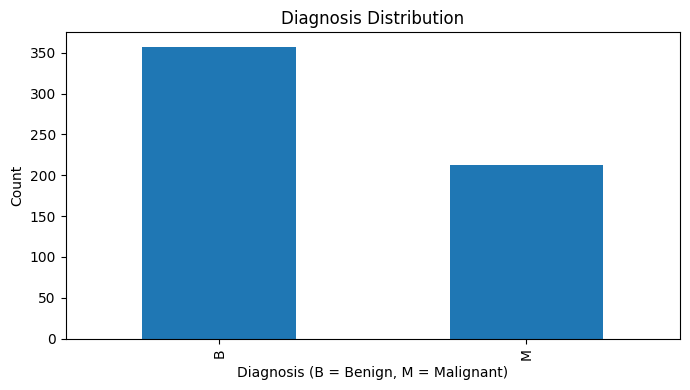

Class proportions:
diagnosis
B    62.74%
M    37.26%
Name: proportion, dtype: object


In [4]:
# Plot the target distribution to check class balance and show why stratified splitting is used.
plt.figure(figsize=(7,4))
df['diagnosis'].value_counts().reindex(['B','M']).plot(kind='bar')
plt.title('Diagnosis Distribution')
plt.xlabel('Diagnosis (B = Benign, M = Malignant)')
plt.ylabel('Count')
plt.tight_layout()
plt.show()
print('Class proportions:')
print(df['diagnosis'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

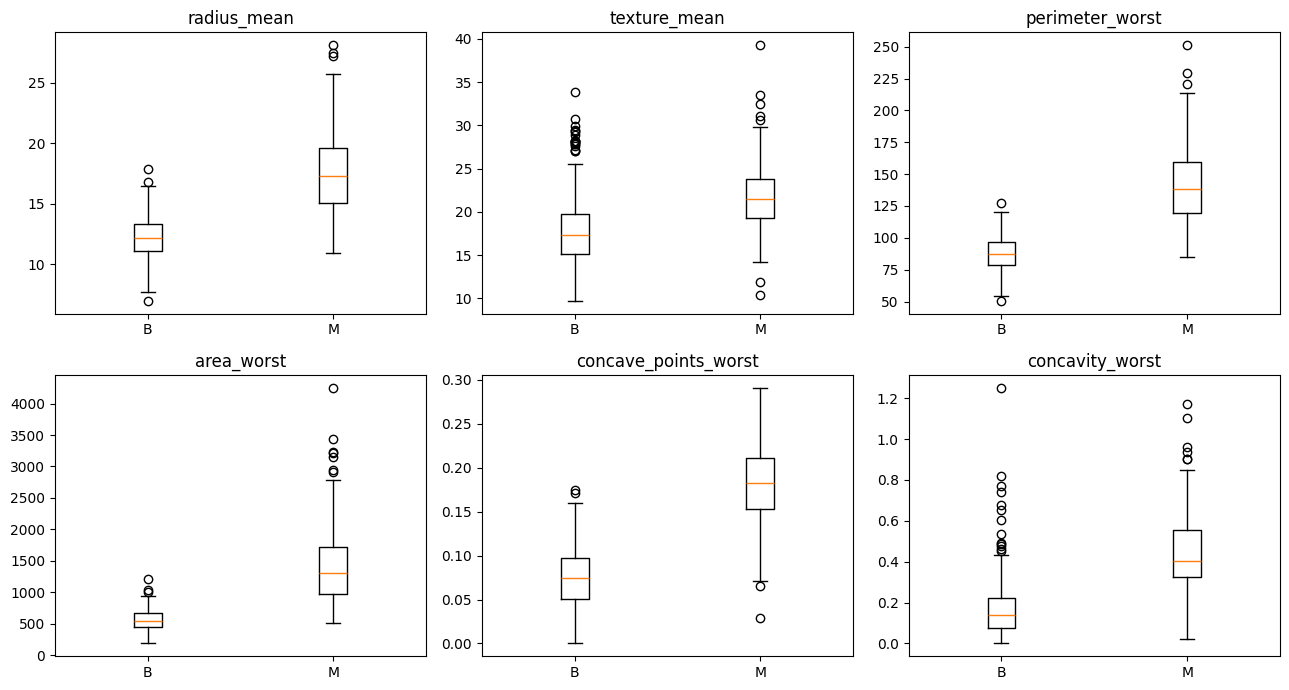

In [5]:
# Compare several high-information features between benign and malignant groups.
selected = ['radius_mean','texture_mean','perimeter_worst','area_worst','concave_points_worst','concavity_worst']
fig, axes = plt.subplots(2,3,figsize=(13,7))
for ax, f in zip(axes.flat, selected):
    ax.boxplot([df.loc[df['diagnosis']=='B', f], df.loc[df['diagnosis']=='M', f]], labels=['B','M'])
    ax.set_title(f)
plt.tight_layout()
plt.show()

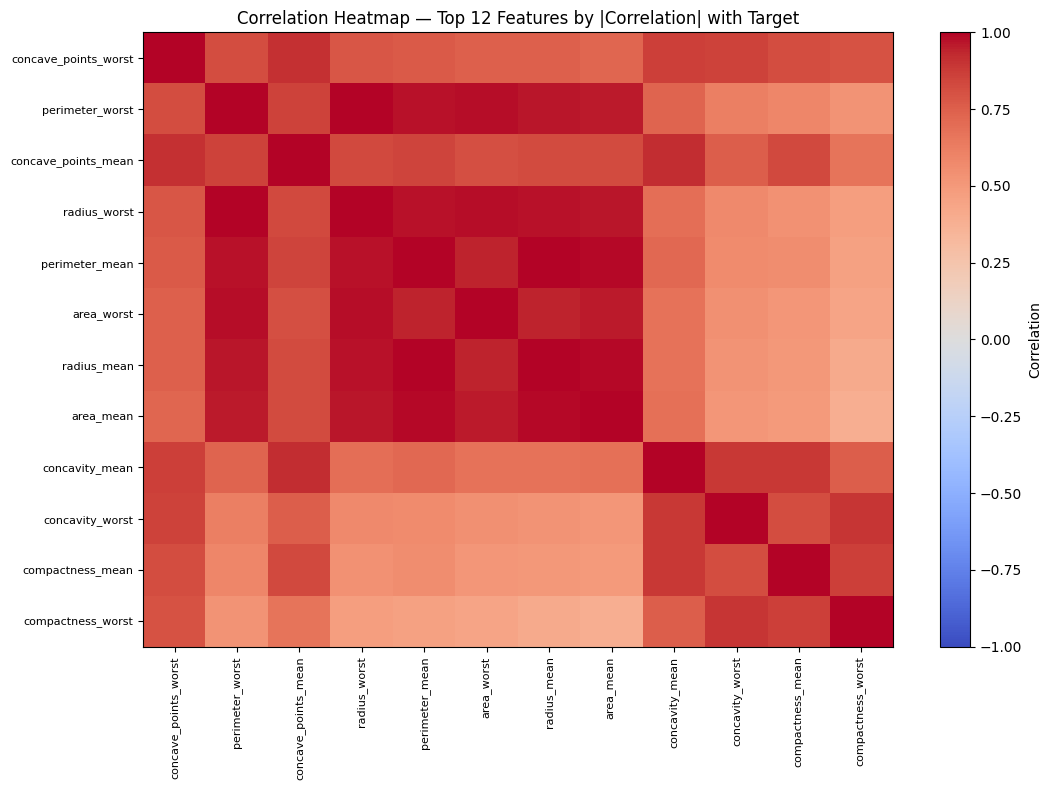

In [6]:
# Examine the feature correlation structure; correlated predictors motivate PCA.
cor = df[feature_cols + ['target']].corr(numeric_only=True)
top_corr = cor['target'].drop('target').abs().sort_values(ascending=False).head(12).index
plt.figure(figsize=(11,8))
corr_matrix = df[list(top_corr)].corr().to_numpy()
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
plt.colorbar(label='Correlation')
plt.xticks(range(len(top_corr)), top_corr, rotation=90, fontsize=8)
plt.yticks(range(len(top_corr)), top_corr, fontsize=8)
plt.title('Correlation Heatmap — Top 12 Features by |Correlation| with Target')
plt.tight_layout()
plt.show()

### Statistical test (CLO2)
We use **Welch's independent-samples t-test** to test whether the mean of each feature differs between benign and malignant groups. Because 30 tests are run, we apply **Benjamini–Hochberg FDR correction** to control the false-discovery rate.

In [7]:
# Run Welch's t-test feature-by-feature and adjust p-values using Benjamini-Hochberg FDR.
rows = []
for f in feature_cols:
    malignant = df.loc[df.target == 1, f]
    benign = df.loc[df.target == 0, f]
    t_stat, p = ttest_ind(malignant, benign, equal_var=False)
    nx, ny = len(malignant), len(benign)
    pooled_sd = np.sqrt(((nx-1)*malignant.var(ddof=1) + (ny-1)*benign.var(ddof=1)) / (nx+ny-2))
    cohen_d = (malignant.mean() - benign.mean()) / pooled_sd
    rows.append([f, malignant.mean(), benign.mean(), t_stat, p, cohen_d])

ttest_df = pd.DataFrame(rows, columns=['Feature','Malignant_Mean','Benign_Mean','t_stat','p_value','Cohen_d'])
ttest_df['p_adj'] = multipletests(ttest_df['p_value'], method='fdr_bh')[1]
ttest_df = ttest_df.sort_values('p_adj')
display(ttest_df.head(10).round(4))

,Feature,Malignant_Mean,Benign_Mean,t_stat,p_value,Cohen_d,p_adj
27,concave_points_worst,0.1822,0.0744,29.1177,0.0,2.6926,0.0
22,perimeter_worst,141.3703,87.0059,25.3322,0.0,2.5982,0.0
7,concave_points_mean,0.0880,0.0257,24.8448,0.0,2.5452,0.0
20,radius_worst,21.1348,13.3798,24.8297,0.0,2.5439,0.0
2,perimeter_mean,115.3654,78.0754,22.9353,0.0,2.2895,0.0
0,radius_mean,17.4628,12.1465,22.2088,0.0,2.2055,0.0
26,concavity_worst,0.4506,0.1662,19.5957,0.0,1.8119,0.0
6,concavity_mean,0.1608,0.0461,20.3324,0.0,2.0033,0.0
23,area_worst,1422.2863,558.8994,20.5708,0.0,2.2302,0.0
3,area_mean,978.3764,462.7902,19.6410,0.0,2.0757,0.0


**Interpretation:** Features related to cell size/shape (for example, concave points, perimeter and radius) show large mean differences between the two diagnosis groups. This gives a statistical basis for the visual patterns seen in the EDA.

## 2. Linear Algebra: Standardization, PCA and SVD (CLO1)

In [8]:
# Standardize each feature so differences in measurement scale do not dominate PCA or distance-based KNN.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Original matrix shape:', X.shape)
print('Standardized matrix shape:', X_scaled.shape)
print('Approx. mean of first 3 features:', X_scaled[:, :3].mean(axis=0).round(6))
print('Approx. std of first 3 features:', X_scaled[:, :3].std(axis=0).round(6))

Original matrix shape: (569, 30)
Standardized matrix shape: (569, 30)
Approx. mean of first 3 features: [-0.  0. -0.]
Approx. std of first 3 features: [1. 1. 1.]


PC1 explains 44.3%
PC2 explains 19.0%
PC1+PC2 explain 63.2%
7 PCs are needed to reach >=90% cumulative explained variance (91.0%)


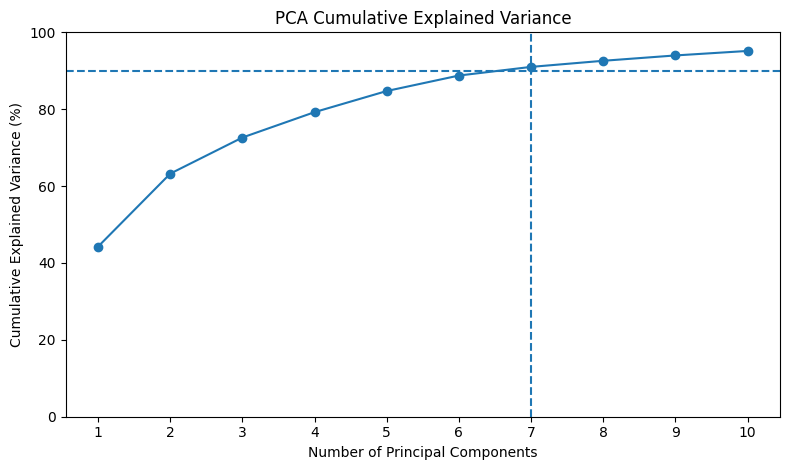

In [9]:
# Run PCA on the standardized matrix and inspect explained variance.
pca = PCA(n_components=10, random_state=42)
X_pca = pca.fit_transform(X_scaled)
explained = pca.explained_variance_ratio_
cumulative = explained.cumsum()
needed_90 = int(np.argmax(cumulative >= 0.90) + 1)
print(f'PC1 explains {explained[0]:.1%}')
print(f'PC2 explains {explained[1]:.1%}')
print(f'PC1+PC2 explain {cumulative[1]:.1%}')
print(f'{needed_90} PCs are needed to reach >=90% cumulative explained variance ({cumulative[needed_90-1]:.1%})')

plt.figure(figsize=(8,4.8))
plt.plot(range(1,11), cumulative*100, marker='o')
plt.axhline(90, linestyle='--')
plt.axvline(needed_90, linestyle='--')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance (%)')
plt.title('PCA Cumulative Explained Variance')
plt.xticks(range(1,11))
plt.ylim(0,100)
plt.tight_layout()
plt.show()

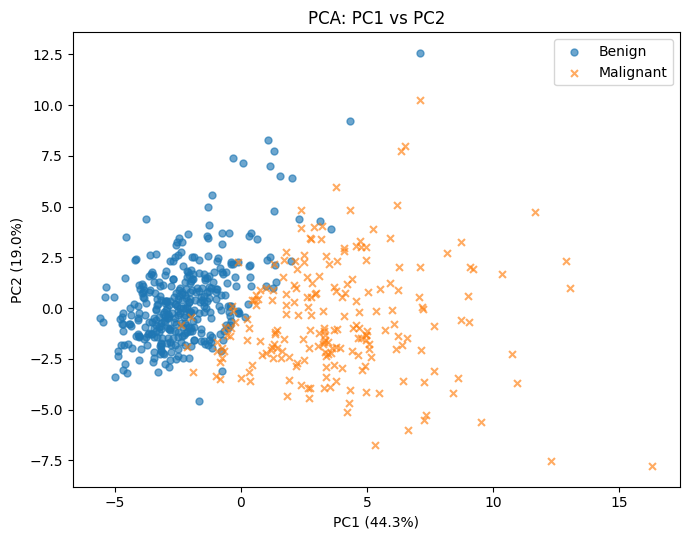

In [10]:
# Visualize the first two principal components to see whether the classes separate in a 2D linear-algebra view.
plt.figure(figsize=(7,5.5))
for label, marker, name in [(0,'o','Benign'), (1,'x','Malignant')]:
    mask = y.values == label
    plt.scatter(X_pca[mask,0], X_pca[mask,1], alpha=0.65, s=25, marker=marker, label=name)
plt.xlabel(f'PC1 ({explained[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({explained[1]*100:.1f}%)')
plt.title('PCA: PC1 vs PC2')
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# Verify the SVD connection: X = U Sigma V^T and PCA variance ratios come from Sigma^2.
U, S, Vt = np.linalg.svd(X_scaled, full_matrices=False)
sigma_ratio = (S**2) / (S**2).sum()
print('First 5 singular values:', np.round(S[:5], 3))
print('PCA vs. SVD variance-ratio match:', np.allclose(sigma_ratio[:10], explained[:10]))
print('Interpretation: larger singular values correspond to directions carrying more standardized-data variance.')

First 5 singular values: [86.932 56.907 40.043 33.571 30.629]
PCA vs. SVD variance-ratio match: True
Interpretation: larger singular values correspond to directions carrying more standardized-data variance.


### PCA interpretation
PC1 captures **44.3%** of total standardized variance and PC2 captures **19.0%**, so the first two components together retain about **63.2%** of the variance. The first 5 PCs retain about **84.7%**, and 6 PCs are enough to exceed 90%. This shows that the 30-dimensional feature space contains substantial redundancy and can be represented more compactly while preserving most variance.

## 3. Train/Test Modeling (CLO3)

In [12]:
# Split once for a held-out test evaluation; stratification preserves the malignant/benign ratio.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print('Train:', X_train.shape, '| Test:', X_test.shape)

# Define three complementary classifiers.
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=5000, random_state=42))
    ]),
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=7))
    ]),
    'Random Forest': RandomForestClassifier(
        n_estimators=400, random_state=42, class_weight='balanced'
    )
}

Train: (455, 30) | Test: (114, 30)


In [13]:
# Train models and evaluate on the unseen test set; do not report training performance as the main result.
metrics = {}
preds, probs = {}, {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:,1]
    preds[name] = pred
    probs[name] = prob
    metrics[name] = {
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, prob)
    }
metrics_df = pd.DataFrame(metrics).T
print(metrics_df.round(4))

                     Accuracy  Precision  Recall      F1  ROC-AUC
Logistic Regression    0.9649     0.9750  0.9286  0.9512   0.9960
KNN                    0.9561     0.9744  0.9048  0.9383   0.9825
Random Forest          0.9737     1.0000  0.9286  0.9630   0.9974


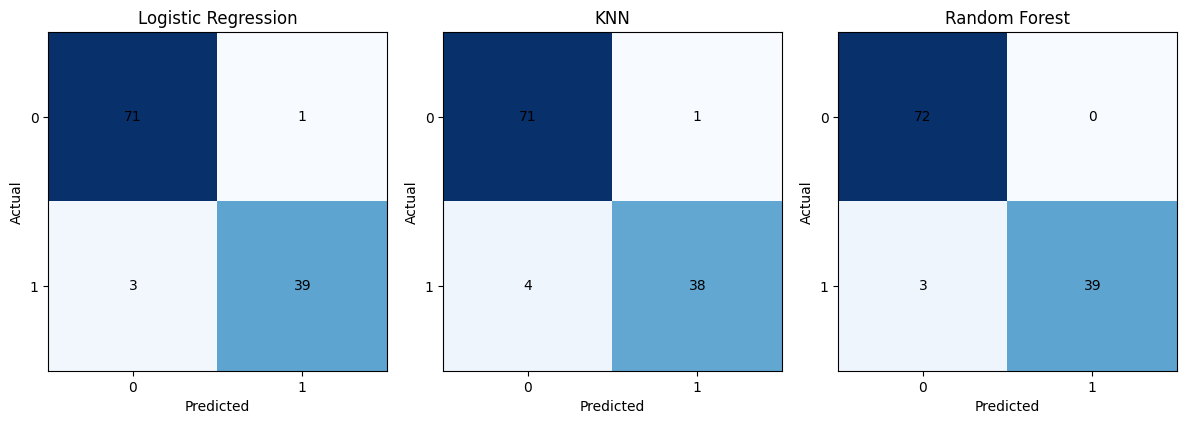

In [14]:
# Show confusion matrices so false positives and false negatives are visible, not hidden inside accuracy.
fig, axes = plt.subplots(1,3,figsize=(12,4))
for ax, (name, pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, pred)
    ax.imshow(cm, cmap='Blues')
    for r in range(cm.shape[0]):
        for c in range(cm.shape[1]):
            ax.text(c, r, str(cm[r,c]), ha='center', va='center')
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_xticks([0,1])
    ax.set_yticks([0,1])
plt.tight_layout()
plt.show()

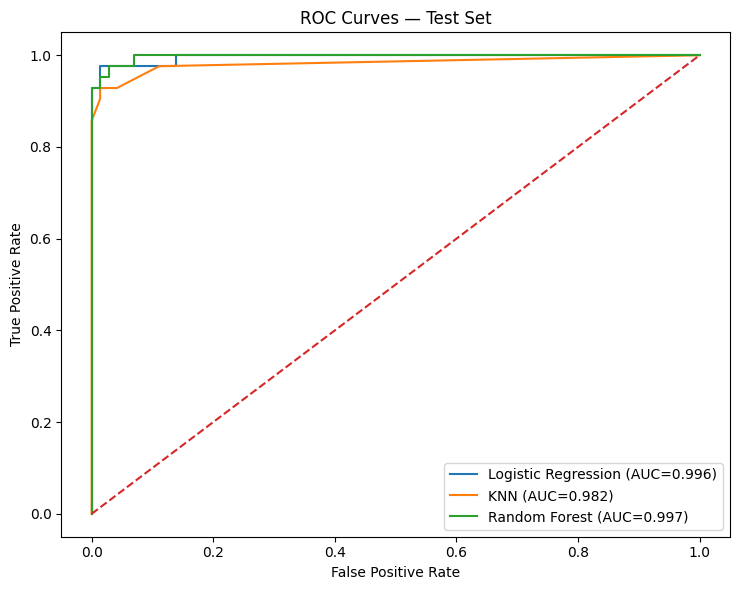

In [15]:
# Compare ROC curves for the held-out test set.
plt.figure(figsize=(7.5,6))
for name, prob in probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, prob):.3f})')
plt.plot([0,1],[0,1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Test Set')
plt.legend()
plt.tight_layout()
plt.show()

### Model interpretation
The test-set results should be read together rather than from accuracy alone. Logistic Regression is attractive for interpretability because its standardized coefficients give a direction and magnitude for each feature. KNN is distance-based, so standardization is essential. Random Forest can model nonlinear interactions and does not require feature scaling.

texture_worst          1.434
radius_se              1.233
symmetry_worst         1.061
concave_points_mean    0.953
concavity_worst        0.911
area_se                0.909
compactness_se        -0.907
area_worst             0.900
radius_worst           0.897
concavity_mean         0.782
dtype: float64


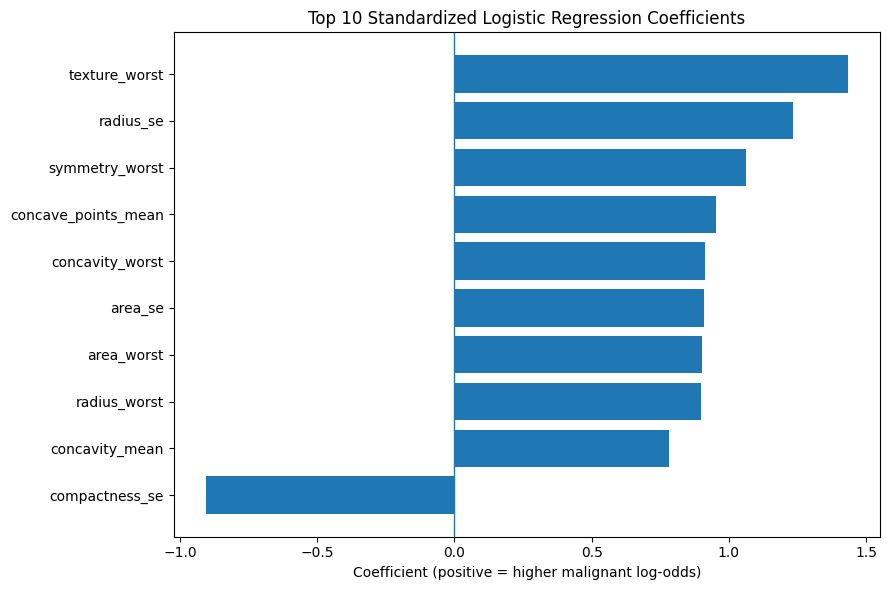

In [16]:
# Inspect the largest absolute standardized Logistic Regression coefficients for interpretation.
log_model = models['Logistic Regression']
coef = pd.Series(log_model.named_steps['model'].coef_[0], index=feature_cols)
coef_sorted = coef.reindex(coef.abs().sort_values(ascending=False).index)
print(coef_sorted.head(10).round(3))

plt.figure(figsize=(9,6))
coef_top = coef_sorted.head(10).sort_values()
plt.barh(coef_top.index, coef_top.values)
plt.axvline(0, linewidth=1)
plt.xlabel('Coefficient (positive = higher malignant log-odds)')
plt.title('Top 10 Standardized Logistic Regression Coefficients')
plt.tight_layout()
plt.show()

## 4. 5-Fold Cross-Validation (CLO4)
A single train/test split can be sensitive to which observations land in the test set. We therefore use **5-fold Stratified Cross-Validation** and compare the same 3 models using accuracy, precision, recall, F1 and ROC-AUC.

In [17]:
# Run stratified 5-fold cross-validation so every fold contains both diagnosis classes.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1','roc_auc':'roc_auc'}
rows = []
for name, model in models.items():
    out = cross_validate(model, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    row = {'Model': name}
    for s in scoring:
        row[f'{s.upper()}_mean'] = out[f'test_{s}'].mean()
        row[f'{s.upper()}_std'] = out[f'test_{s}'].std(ddof=1)
    rows.append(row)
cv_df = pd.DataFrame(rows)
display(cv_df.round(4))

,Model,ACCURACY_mean,ACCURACY_std,PRECISION_mean,PRECISION_std,RECALL_mean,RECALL_std,F1_mean,F1_std,ROC_AUC_mean,ROC_AUC_std
0,Logistic Regression,0.9737,0.0186,0.9863,0.0204,0.9436,0.0587,0.9633,0.0268,0.9953,0.0060
1,KNN,0.9649,0.0205,0.9856,0.0208,0.9200,0.0632,0.9505,0.0303,0.9863,0.0123
2,Random Forest,0.9613,0.0159,0.9596,0.0401,0.9388,0.0610,0.9472,0.0227,0.9899,0.0084


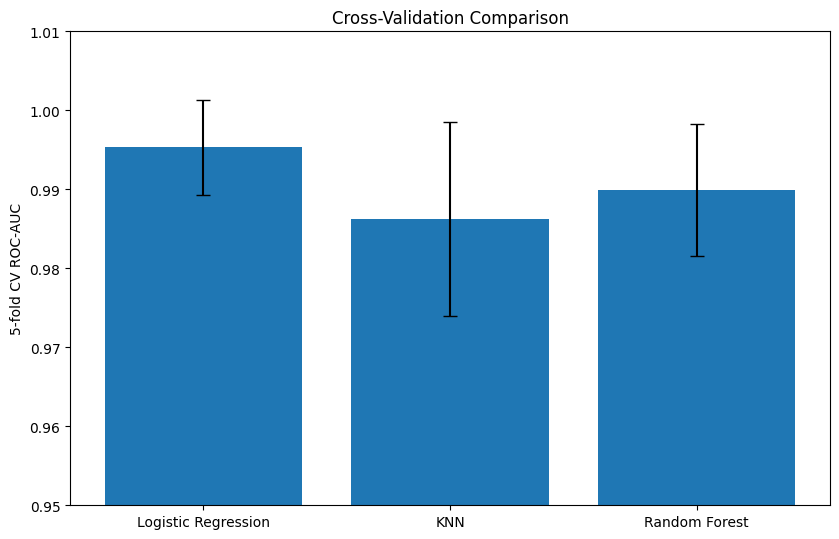

Selected model under CV ROC-AUC: Logistic Regression (mean=0.9953, std=0.0060)


In [18]:
# Plot mean ROC-AUC with one-standard-deviation error bars across the 5 folds.
plt.figure(figsize=(8.5,5.5))
x = np.arange(len(cv_df))
plt.bar(x, cv_df['ROC_AUC_mean'], yerr=cv_df['ROC_AUC_std'], capsize=5)
plt.xticks(x, cv_df['Model'])
plt.ylim(0.95,1.01)
plt.ylabel('5-fold CV ROC-AUC')
plt.title('Cross-Validation Comparison')
plt.tight_layout()
plt.show()

best_cv = cv_df.sort_values('ROC_AUC_mean', ascending=False).iloc[0]
print(f"Selected model under CV ROC-AUC: {best_cv['Model']} (mean={best_cv['ROC_AUC_mean']:.4f}, std={best_cv['ROC_AUC_std']:.4f})")

### Cross-validation interpretation
In this run, **Logistic Regression has the highest mean 5-fold ROC-AUC (~0.995)**, while Random Forest remains very close (~0.990). The important lesson for the project is that the model choice should be supported by repeated validation rather than a single holdout score.

## 5. Bonus: Bootstrap Uncertainty of Logistic Regression Coefficients

In [19]:
# Bootstrap the training set 250 times to estimate 95% intervals for standardized Logistic Regression coefficients.
rng = np.random.default_rng(42)
boot_coefs = []
for _ in range(250):
    idx = rng.integers(0, len(X_train), len(X_train))
    xb, yb = X_train.iloc[idx], y_train.iloc[idx]
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=5000, random_state=42))
    ])
    pipe.fit(xb, yb)
    boot_coefs.append(pipe.named_steps['model'].coef_[0])
boot_coefs = np.vstack(boot_coefs)
base_coef = log_model.named_steps['model'].coef_[0]
ci_low = np.percentile(boot_coefs, 2.5, axis=0)
ci_high = np.percentile(boot_coefs, 97.5, axis=0)
boot_df = pd.DataFrame({'Feature':feature_cols,'Coefficient':base_coef,'CI_low':ci_low,'CI_high':ci_high})
boot_df['AbsCoef'] = boot_df['Coefficient'].abs()
boot_df = boot_df.sort_values('AbsCoef', ascending=False)
display(boot_df.head(10).round(3))

,Feature,Coefficient,CI_low,CI_high,AbsCoef
21,texture_worst,1.434,0.832,1.964,1.434
10,radius_se,1.233,0.577,1.879,1.233
28,symmetry_worst,1.061,0.559,1.434,1.061
7,concave_points_mean,0.953,0.500,1.363,0.953
26,concavity_worst,0.911,0.627,1.262,0.911
13,area_se,0.909,0.618,1.229,0.909
15,compactness_se,-0.907,-1.478,-0.470,0.907
23,area_worst,0.900,0.686,1.093,0.900
20,radius_worst,0.897,0.614,1.160,0.897
6,concavity_mean,0.782,0.393,1.120,0.782


## 6. Final Data Story & Conclusion

1. **EDA:** The diagnosis classes are not perfectly balanced, so stratification is used for splitting and cross-validation.
2. **Statistics:** Many cell-size/shape features have large standardized differences between benign and malignant observations after FDR correction.
3. **Linear Algebra:** Standardization + PCA shows that a small number of orthogonal components capture most variance; PC1 alone explains ~44.3%. SVD provides the same variance structure through singular values.
4. **Modeling:** Logistic Regression, KNN and Random Forest all achieve strong held-out test performance.
5. **Validation:** 5-fold CV gives a more stable comparison; Logistic Regression has the highest mean ROC-AUC in this run.
6. **Story:** The dataset contains substantial redundancy among correlated morphology measurements. Linear algebra compresses that information, statistics confirms strong group differences, and cross-validation helps distinguish robust performance from one lucky split.

> **Limitation:** This is a public benchmark dataset and the analysis is for coursework. Model performance here should not be interpreted as clinical accuracy in a real hospital setting.

## Final Checklist vs Rubric

- ✅ ≥500 rows and ≥5 predictors
- ✅ CLO1: PCA + SVD + interpretation
- ✅ CLO2: EDA + statistical test + interpretation
- ✅ CLO3: 3 models + test metrics + confusion matrix + ROC curve
- ✅ CLO4: 5-fold CV for 3 models + plot + model selection
- ✅ Code comments in every code block
- ✅ Bonus: Bootstrap coefficient uncertainty + data storytelling
- ✅ Test-set performance reported instead of training-only performance
- ✅ Standardization before Logistic Regression / KNN